# 02 Logistic Regression (baseline)
Three variants that handle multicollinearity differently:
1. **Plain logistic** on a hand-pruned + VIF-pruned feature set (all VIF <= 5).
2. **L1 (lasso)** on all features: the penalty does the feature selection.
3. **Elastic net** on all features: keeps correlated groups together.

Features are standardized inside each CV fold (pipeline), so there is no leakage.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # project root, so `src` is importable

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import RocCurveDisplay

from src.modeling import (SEED, get_cv, load_split, linear_features, pruned_linear_features,
                          raw_features, vif, best_cv_scores, cv_summary, finalize, load_scores)

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_rows", 80)

fs = load_split()
X_train, y_train, X_test, y_test = fs.X_train, fs.y_train, fs.X_test, fs.y_test
cv = get_cv()   # 5-fold x 5 repeats, stratified, same splits in every notebook
print(X_train.shape, X_test.shape, "| train quit rate", round(y_train.mean(), 3))

(1170, 53) (300, 53) | train quit rate 0.158


## 1. Plain logistic on pruned features
Hand pruning removes exact linear combinations and the income/level redundancy, then iterative VIF pruning drops the worst remaining offenders. VIF ignores `y`, so pruning on the training set does not leak the target.

In [2]:
print("VIF before pruning (top 10):")
display(vif(X_train[linear_features(X_train)]).head(10).round(1))

pruned_cols = pruned_linear_features(X_train)
print(f"\n{len(pruned_cols)} features kept")
vif(X_train[pruned_cols]).round(2).to_frame("VIF").T

VIF before pruning (top 10):


Age                                   inf
YearsSinceLastPromotion               inf
YearsAtCompany                        inf
TravelOrd                             inf
BusinessTravel_Non-Travel             inf
AgeAtJoin                             inf
StagnationYears                       inf
BusinessTravel_Travel_Frequently      inf
MonthlyIncome                       172.7
JobLevel                            147.5
dtype: float64

drop YearsAtCompany                      VIF=15.7


drop TotalWorkingYears                   VIF=11.3
drop YearsInCurrentRole                  VIF=9.7
drop NumCompaniesWorked                  VIF=7.8
drop YearsWithCurrManager                VIF=6.2



32 features kept


,LogIncome,YearsSinceLastPromotion,PromoGap,JobRole_Manager,IncomePerYearWork,NewHire,FarFromHome,EarlyCareer,DistanceFromHome,TenureRatio,...,OT_x_Travel,MaritalStatus_Single,JobRole_Laboratory Technician,JobHopper,JobRole_Sales Representative,TravelOrd,MaritalStatus_Divorced,JobRole_Human Resources,Education,Male
VIF,7.42,4.31,3.55,3.52,3.13,3.1,3.1,3.1,3.09,3.04,...,1.59,1.59,1.56,1.39,1.38,1.32,1.17,1.15,1.05,1.04


In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, GridSearchCV

logit_plain = make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000))
plain_scores = cross_val_score(logit_plain, X_train[pruned_cols], y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
print("Plain logistic (pruned):", cv_summary(plain_scores))

Plain logistic (pruned): CV AUC 0.8153 +/- 0.0411 (25 folds)


,coef_per_SD,odds_ratio_per_SD
JobRole_Research Director,-0.434,0.648
LogIncome,-0.427,0.652
Age,-0.296,0.744
RoleRatio,-0.278,0.757
JobRole_Manufacturing Director,-0.238,0.788
JobRole_Manager,-0.229,0.796
MaritalStatus_Divorced,-0.210,0.811
MgrRatio,-0.196,0.822
OT_x_Travel,-0.153,0.858
JobRole_Healthcare Representative,-0.113,0.893


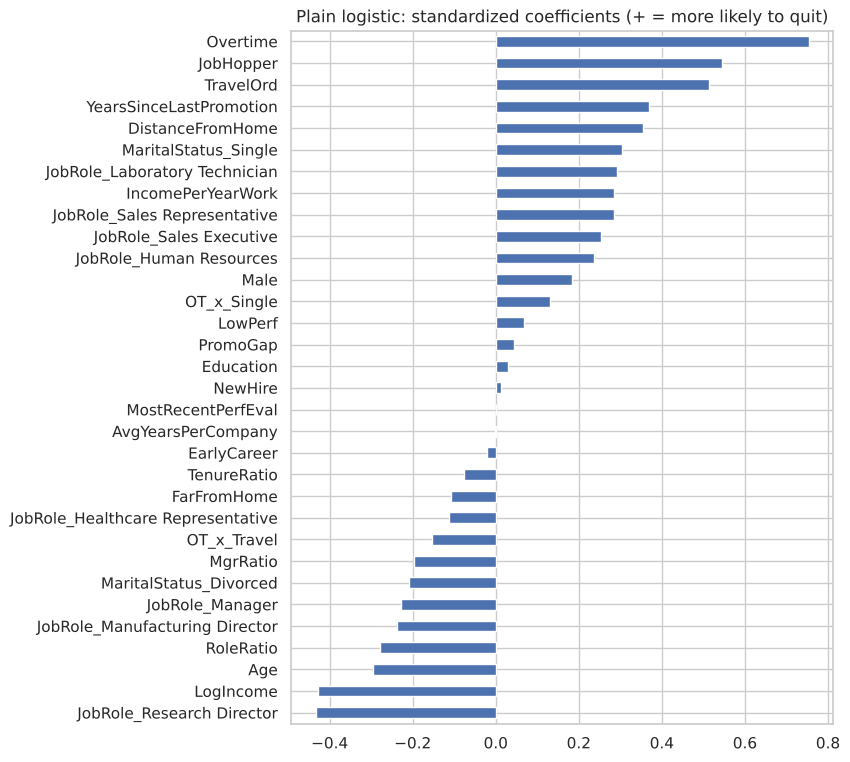

In [4]:
logit_plain.fit(X_train[pruned_cols], y_train)
coef = pd.Series(logit_plain[-1].coef_[0], index=pruned_cols)
odds = pd.DataFrame({"coef_per_SD": coef, "odds_ratio_per_SD": np.exp(coef)}).sort_values("coef_per_SD")
display(odds.round(3))
odds["coef_per_SD"].plot.barh(figsize=(7, 9), title="Plain logistic: standardized coefficients (+ = more likely to quit)")
plt.show()

## 2. L1 (lasso) logistic on all features
Tune the penalty strength `C` by CV AUC. Smaller `C` = stronger penalty = fewer features.

best C: 0.3162 | CV AUC 0.8165 +/- 0.0388 (25 folds)


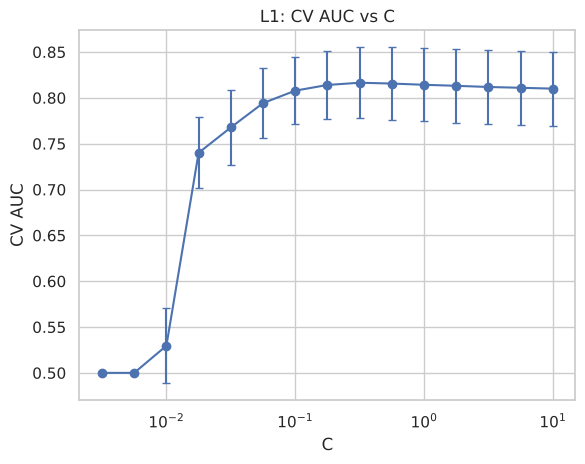

In [5]:
lin_cols = linear_features(X_train)
l1 = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1.0, solver="saga", max_iter=20000))
l1_search = GridSearchCV(l1, {"logisticregression__C": np.logspace(-2.5, 1, 15)},
                         cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train[lin_cols], y_train)
l1_scores = best_cv_scores(l1_search)
print("best C:", round(l1_search.best_params_["logisticregression__C"], 4), "|", cv_summary(l1_scores))

res = pd.DataFrame(l1_search.cv_results_)
plt.errorbar(res["param_logisticregression__C"].astype(float), res["mean_test_score"], yerr=res["std_test_score"], marker="o", capsize=3)
plt.xscale("log"); plt.xlabel("C"); plt.ylabel("CV AUC"); plt.title("L1: CV AUC vs C"); plt.show()

30 of 47 features kept by L1
dropped: ['Age', 'AvgYearsPerCompany', 'BusinessTravel_Travel_Frequently', 'Department_Human Resources', 'EarlyCareer', 'Education', 'FarFromHome', 'IncomePerAge', 'IncomePerLevel', 'JobLevel', 'MonthlyIncome', 'MostRecentPerfEval', 'StagnationYears', 'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsWithCurrManager']


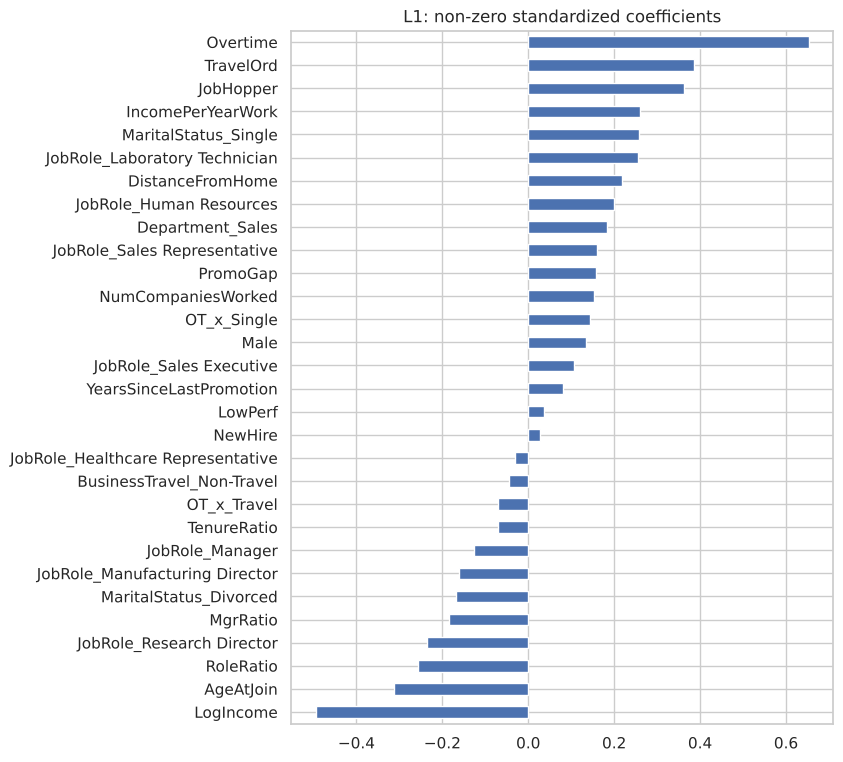

In [6]:
l1_coef = pd.Series(l1_search.best_estimator_[-1].coef_[0], index=lin_cols)
print(f"{(l1_coef != 0).sum()} of {len(lin_cols)} features kept by L1")
print("dropped:", sorted(l1_coef[l1_coef == 0].index))
l1_coef[l1_coef != 0].sort_values().plot.barh(figsize=(7, 9), title="L1: non-zero standardized coefficients")
plt.show()

## 3. Elastic net on all features

best: {'C': np.float64(0.0681), 'l1_ratio': 0.1} | CV AUC 0.8182 +/- 0.0374 (25 folds)


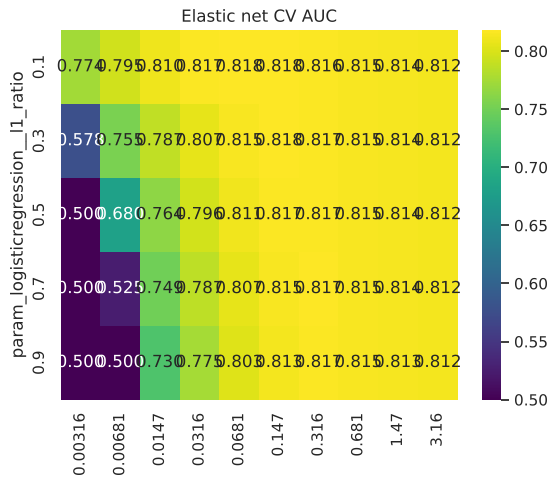

In [7]:
en = make_pipeline(StandardScaler(), LogisticRegression(solver="saga", max_iter=20000))
en_grid = {"logisticregression__C": np.logspace(-2.5, 0.5, 10),
           "logisticregression__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]}
en_search = GridSearchCV(en, en_grid, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train[lin_cols], y_train)
en_scores = best_cv_scores(en_search)
print("best:", {k.split("__")[1]: round(v, 4) for k, v in en_search.best_params_.items()}, "|", cv_summary(en_scores))

piv = pd.DataFrame(en_search.cv_results_).pivot_table(index="param_logisticregression__l1_ratio",
                                                      columns="param_logisticregression__C", values="mean_test_score")
piv.columns = [f"{c:.3g}" for c in piv.columns]
sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis"); plt.title("Elastic net CV AUC"); plt.show()

40 of 47 features non-zero


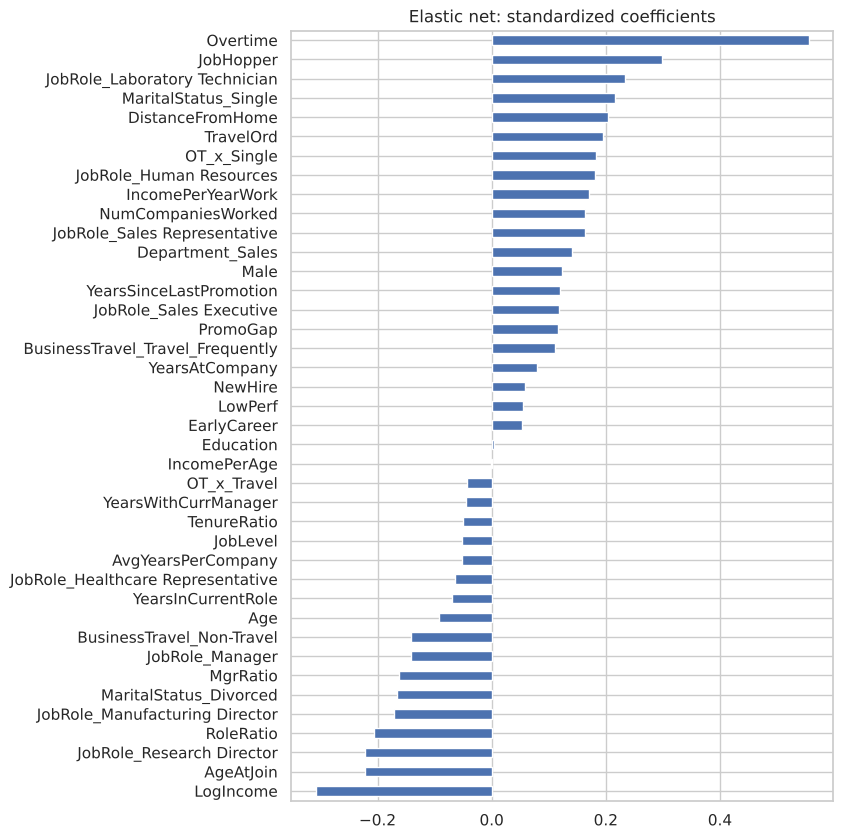

In [8]:
en_coef = pd.Series(en_search.best_estimator_[-1].coef_[0], index=lin_cols)
print(f"{(en_coef != 0).sum()} of {len(lin_cols)} features non-zero")
en_coef[en_coef != 0].sort_values().plot.barh(figsize=(7, 10), title="Elastic net: standardized coefficients")
plt.show()

## Compare the three variants (CV, training data only)

,mean,std
plain_pruned,0.8153,0.0420
l1,0.8165,0.0396
elastic_net,0.8182,0.0382


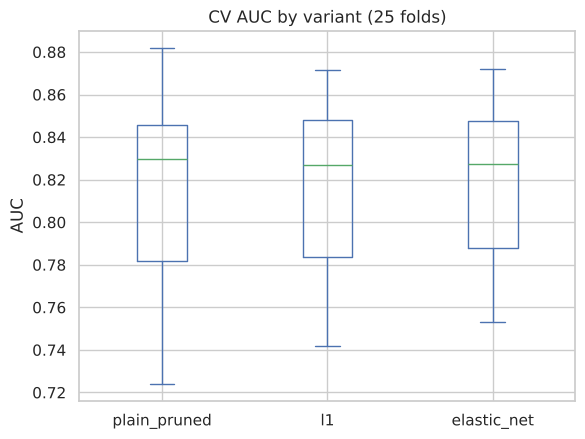

In [9]:
cmp = pd.DataFrame({"plain_pruned": plain_scores, "l1": l1_scores, "elastic_net": en_scores})
display(cmp.agg(["mean", "std"]).T.round(4))
cmp.plot.box(title="CV AUC by variant (25 folds)"); plt.ylabel("AUC"); plt.show()

## Test set (scored once)
The model is frozen above. This is the only cell that touches `y_test`. It also saves test predictions and out-of-fold training predictions to `results/preds/` for blending later.

In [10]:
finalize("logit_plain_pruned", logit_plain, X_train[pruned_cols], y_train, X_test[pruned_cols], y_test,
         fs.id_train, fs.id_test, plain_scores, notes="no penalty, hand + VIF pruned")
finalize("logit_l1", l1_search.best_estimator_, X_train[lin_cols], y_train, X_test[lin_cols], y_test,
         fs.id_train, fs.id_test, l1_scores, notes=f"C={l1_search.best_params_['logisticregression__C']:.3g}")
finalize("logit_elasticnet", en_search.best_estimator_, X_train[lin_cols], y_train, X_test[lin_cols], y_test,
         fs.id_train, fs.id_test, en_scores,
         notes=", ".join(f"{k.split('__')[1]}={v:.3g}" for k, v in en_search.best_params_.items()));

logit_plain_pruned: CV AUC 0.8153 +/- 0.0411 (25 folds) | TEST AUC 0.7760


logit_l1: CV AUC 0.8165 +/- 0.0388 (25 folds) | TEST AUC 0.7690
logit_elasticnet: CV AUC 0.8182 +/- 0.0374 (25 folds) | TEST AUC 0.7650


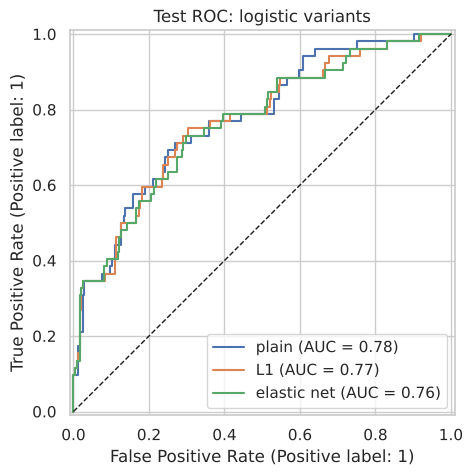

In [11]:
fig, ax = plt.subplots(figsize=(5, 5))
for label, model, cols in [("plain", logit_plain, pruned_cols), ("L1", l1_search.best_estimator_, lin_cols),
                           ("elastic net", en_search.best_estimator_, lin_cols)]:
    RocCurveDisplay.from_predictions(y_test, model.predict_proba(X_test[cols])[:, 1], name=label, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_title("Test ROC: logistic variants"); plt.show()

## Leaderboard so far

In [12]:
load_scores()

,model,cv_auc_mean,cv_auc_std,test_auc,n_features,notes
0,logit_elasticnet,0.8182,0.0374,0.765,47,"C=0.0681, l1_ratio=0.1"
1,logit_l1,0.8165,0.0388,0.769,47,C=0.316
2,logit_plain_pruned,0.8153,0.0411,0.776,32,"no penalty, hand + VIF pruned"
